En este fichero realizaremos un modelo de clasificación de casas basado en los datos de diferentes portales inmobiliarios.

In [9]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [10]:
%%R
lib_loc <- "lib_loc_10"

In [11]:
%%R
os <- Sys.info()[["sysname"]]

Cargamos librerias

In [142]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))

if (!require("psych", lib.loc = lib_loc)) install.packages("psych", lib = lib_loc)
library(psych, lib.loc = lib_loc)
if (!require("plyr", lib.loc = lib_loc)) install.packages("plyr", lib = lib_loc)
library(plyr, lib.loc = lib_loc)
if (!require("Rmisc", lib.loc = lib_loc)) install.packages("Rmisc", lib = lib_loc)
library(Rmisc, lib.loc = lib_loc)
if (!require("dplyr", lib.loc = lib_loc)) install.packages("dplyr", lib = lib_loc)
library(dplyr, lib.loc = lib_loc)
if (!require("GGally", lib.loc = lib_loc)) install.packages("GGally", lib = lib_loc)
library(GGally, lib.loc = lib_loc)
if (!require("corrplot", lib.loc = lib_loc)) install.packages("corrplot", lib = lib_loc)
library(corrplot, lib.loc = lib_loc)
if (!require("survey", lib.loc = lib_loc)) install.packages("survey", lib = lib_loc)
library(survey, lib.loc = lib_loc)
if (!require("mitools", lib.loc = lib_loc)) install.packages("mitools", lib = lib_loc)
library(mitools, lib.loc = lib_loc)
if (!require("relaimpo", lib.loc = lib_loc)) install.packages("relaimpo", lib = lib_loc)
library(relaimpo, lib.loc = lib_loc)
if (!require("FSelectorRcpp", lib.loc = lib_loc)) install.packages("FSelectorRcpp", lib = lib_loc)
library(FSelectorRcpp, lib.loc = lib_loc)
if (!require("ranger", lib.loc = lib_loc)) install.packages("ranger", lib = lib_loc)
library(ranger, lib.loc = lib_loc)
if (!require("Boruta", lib.loc = lib_loc)) install.packages("Boruta", lib = lib_loc)
library(Boruta, lib.loc = lib_loc)
if (!require("randomForest", lib.loc = lib_loc)) install.packages("randomForest", lib = lib_loc)
library(randomForest, lib.loc = lib_loc)
if (!require("caret", lib.loc = lib_loc)) install.packages("caret", lib = lib_loc)
library(caret, lib.loc = lib_loc)
if (!require("e1071", lib.loc = lib_loc)) install.packages("e1071", lib = lib_loc)
library(e1071, lib.loc = lib_loc)

if (!require("ggsci", lib.loc = lib_loc)) install.packages("ggsci", lib = lib_loc)
library(ggsci, lib.loc = lib_loc)
if (!require("dendextend", lib.loc = lib_loc)) install.packages("dendextend", lib = lib_loc)
library(dendextend, lib.loc = lib_loc)
if (!require("factoextra", lib.loc = lib_loc)) install.packages("factoextra", lib = lib_loc)
library(factoextra, lib.loc = lib_loc)
if (!require("FactoMineR", lib.loc = lib_loc)) install.packages("FactoMineR", lib = lib_loc)
library(FactoMineR, lib.loc = lib_loc)
if (!require("nFactors", lib.loc = lib_loc)) install.packages("nFactors", lib = lib_loc)
library(nFactors, lib.loc = lib_loc)

if (!require("caTools", lib.loc = lib_loc)) install.packages("caTools", lib = lib_loc)
library(caTools, lib.loc = lib_loc)
if (!require("caret", lib.loc = lib_loc)) install.packages("caret", lib = lib_loc)
library(caret, lib.loc = lib_loc)
if (!require("e1071", lib.loc = lib_loc)) install.packages("e1071", lib = lib_loc)
library(e1071, lib.loc = lib_loc)
if (!require("ROSE", lib.loc = lib_loc)) install.packages("ROSE", lib = lib_loc)
library(ROSE, lib.loc = lib_loc)
if (!require("kernlab", lib.loc = lib_loc)) install.packages("kernlab", lib = lib_loc)
library(kernlab, lib.loc = lib_loc)
if (!require("themis", lib.loc = lib_loc)) install.packages("themis", lib = lib_loc)
library(themis, lib.loc = lib_loc)

if (!require("randomForest", lib.loc = lib_loc)) install.packages("randomForest", lib = lib_loc)
library(randomForest, lib.loc = lib_loc)

if (!require("xgboost", lib.loc = lib_loc)) install.packages("xgboost", lib = lib_loc)
library(xgboost, lib.loc = lib_loc)


if(os=="Darwin"){
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps_3.2.tgz", lib = lib_loc, repos = NULL, type = "mac.binary")
    library(leaps, lib.loc = lib_loc)
}else{
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps", lib = lib_loc)
    library(leaps, lib.loc = lib_loc)
}


The downloaded binary packages are in
	/var/folders/1d/8y2whlcd4cx508sll_rm0nwh0000gn/T//RtmpjD3Er2/downloaded_packages


Loading required package: xgboost
trying URL 'https://cloud.r-project.org/bin/macosx/big-sur-arm64/contrib/4.5/xgboost_3.1.2.1.tgz'
Content type 'application/x-gzip' length 24498966 bytes (23.4 MB)
downloaded 23.4 MB

In addition: Warning messages:
1: In library(package, lib.loc = lib.loc, character.only = TRUE, logical.return = TRUE,  :
  there is no package called ‘xgboost’
2: package ‘xgboost’ was built under R version 4.5.2 


# Carga del fichero

In [13]:
%%R

dfMedidas <- read.csv("apartment+for+rent+classified/apartments_for_rent_classified_10K.csv", 
                      sep = ";", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)


# Visualizamos los datos

In [14]:
%%R
head(dfMedidas, 5)

          id               category
1 5668626895 housing/rent/apartment
2 5664597177 housing/rent/apartment
3 5668626833 housing/rent/apartment
4 5659918074 housing/rent/apartment
5 5668626759 housing/rent/apartment
                                                                title
1 Studio apartment 2nd St NE, Uhland Terrace NE, Washington, DC 20002
2                                   Studio apartment 814 Schutte Road
3         Studio apartment N Scott St, 14th St N, Arlington, VA 22209
4                                      Studio apartment 1717 12th Ave
5         Studio apartment Washington Blvd, N Cleveland St, Arlington
                                                                                                                                                                                     body
1 This unit is located at second St NE, Uhland Terrace NE, Washington, DC 20002, Washington, 20002, DCMonthly rental rates range from $790 - $1090We have studio units available f

Analizamos los tipos de variables

In [15]:
%%R
str(dfMedidas)

'data.frame':	10000 obs. of  22 variables:
 $ id           : num  5.67e+09 5.66e+09 5.67e+09 5.66e+09 5.67e+09 ...
 $ category     : Factor w/ 3 levels "housing/rent/apartment",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ title        : Factor w/ 9350 levels ". Sierra. Unit A Reno, NV",..: 5997 6365 6452 5823 6468 82 5936 6455 6056 6427 ...
 $ body         : Factor w/ 9961 levels "- 3 beds / 2 baths Apartment for Lease in an eight-plex in. - Freshly painted. - Laminate floor in Living Room,"| __truncated__,..: 9391 8488 9281 4394 9530 28 5318 9310 6140 8996 ...
 $ amenities    : Factor w/ 2255 levels "AC","AC,Alarm,Cable or Satellite,Clubhouse,Dishwasher,Fireplace,Garbage Disposal,Internet Access,Parking,Patio/Deck,"| __truncated__,..: 2137 2137 2137 2137 2137 1587 2137 2137 2239 2137 ...
 $ bathrooms    : Factor w/ 15 levels "1","1.5","2",..: 15 15 1 1 15 1 15 15 1 15 ...
 $ bedrooms     : Factor w/ 11 levels "0","1","2","3",..: 1 2 1 1 1 1 1 1 1 1 ...
 $ currency     : Factor w/ 1 level "USD": 1 1

# EDA

Como podemos observar hay un total de 8760 instancias con 22 variables.
Estas variables se pueden dividir en categóricas, numéricas y una ordinal:

1)   Categóricas:
* category (Variable Objetivo): Categoría de la casa
* title: Título de la oferta
* body: Cuerpo de la oferta
* amenities: Comodidades
* currency: Moneda en la que está el precio
* has_photo: Tiene foto del apartamento o no
* pets_allowed: Permite o no mascotas (None, o lista con las opciones)
* price_display: Precio pero con el símbolo de la moneda en la que está
* price_type: Tipo de pago (Mensual, ...)
* cityname: Ciudad
* state: Estado
* source: Plataforma donde está la oferta


2)   Numéricas:
* id: Identificador de la casa
* bathrooms: Número de baños
* bedrooms: Número de habitaciones
* price: Precio de la casa (Número)
* latitude: Coordenada de latitud
* longitude: Coordenada de longitud
* address: Dirección
* fee: Señal (Número o "No")
* square_feet: Metros cuadrados

3) Ordinales:
* time: Tiempo desde que se creó la oferta


Cabe destacar que muchos de los valores numéricos no son de tipo entero, por lo que habrá que tratar los datos antes de tratar con ellos.
Por otro lado, muchos de los campos tienen el valor "null" para denotar falta de datos, sin embargo, no se clasifican como valores faltantes.

Para conocer los datos con más detalle hay que evaluar los siguientes conceptos:


*   Columnas faltantes o irrelevantes
*   Variables categóricas con mayor cardinalidad
*   Variables con valores faltantes
*   Correlación de las variables numéricas

In [16]:
%%R
describe(dfMedidas)

               vars     n         mean          sd       median      trimmed
id                1 10000 5.623396e+09 70210252.04 5668609592.5 5.632060e+09
category*         2 10000 1.000000e+00        0.03          1.0 1.000000e+00
title*            3 10000 4.579810e+03     2745.64       4624.5 4.564870e+03
body*             4 10000 4.978490e+03     2883.11       4976.5 4.977060e+03
amenities*        5 10000 1.701780e+03      610.95       2073.0 1.812630e+03
bathrooms*        6 10000 1.810000e+00        1.45          1.0 1.560000e+00
bedrooms*         7 10000 2.750000e+00        0.97          3.0 2.620000e+00
currency*         8 10000 1.000000e+00        0.00          1.0 1.000000e+00
fee*              9 10000 1.000000e+00        0.00          1.0 1.000000e+00
has_photo*       10 10000 2.070000e+00        0.32          2.0 2.000000e+00
pets_allowed*    11 10000 2.970000e+00        1.29          2.0 2.900000e+00
price            12 10000 1.486280e+03     1076.51       1270.0 1.331120e+03

En este caso podemos ver que hay algunas columnas irrelevantes, ya sea por ser de id o que no aporten información como id; title; body; price_display; address, o amenities o por ser de valores constantes como fee y currency.

En cuanto a la cardinalidad máxima podemos ver que la variable con mayor rango es el nombre de la ciudad, alcanzndo los 1574 valores.

En cuanto a los valores faltantes, hay que tratar los datos para que se identifiquen los null como valores nulos

Transformamos los valores nulos para que se detecten como tal y luego eliminaremos las columnas innecesarias y con muchos nulos.

In [17]:
%%R

dfMedidas <- read.csv("apartment+for+rent+classified/apartments_for_rent_classified_10K.csv", 
                      sep = ";", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = FALSE, 
                      na.strings = c("null", "NULL", "", " ", "NA", "None"),
                      header = TRUE, 
                      fill = TRUE)

In [18]:
%%R 
data.frame(
  NAs = colSums(is.na(dfMedidas)),
  Perc = colSums(is.na(dfMedidas)) / nrow(dfMedidas) * 100
)

               NAs  Perc
id               0  0.00
category         0  0.00
title            0  0.00
body             0  0.00
amenities     3549 35.49
bathrooms       34  0.34
bedrooms         7  0.07
currency         0  0.00
fee              0  0.00
has_photo        0  0.00
pets_allowed  4163 41.63
price            0  0.00
price_display    0  0.00
price_type       0  0.00
square_feet      0  0.00
address       3327 33.27
cityname        77  0.77
state           77  0.77
latitude        10  0.10
longitude       10  0.10
source           0  0.00
time             0  0.00


In [19]:
%%R

dfMedidas <- dfMedidas[,!names(dfMedidas) %in% c("id", "title", "body", "price_display", "address", "amenities", "fee", "currency", "amenities", "pets_allowed")]

In [20]:
%%R
describe(dfMedidas)

            vars     n          mean         sd        median       trimmed
category*      1 10000          1.00       0.03          1.00          1.00
bathrooms      2  9966          1.38       0.62          1.00          1.27
bedrooms       3  9993          1.74       0.94          2.00          1.62
has_photo*     4 10000          2.07       0.32          2.00          2.00
price          5 10000       1486.28    1076.51       1270.00       1331.12
price_type*    6 10000          1.00       0.02          1.00          1.00
square_feet    7 10000        945.81     655.76        802.00        863.80
cityname*      8  9923        727.11     455.05        741.00        720.69
state*         9  9923         27.43      15.37         28.00         27.73
latitude      10  9990         37.70       5.50         38.81         37.56
longitude     11  9990        -94.65      15.76        -93.65        -93.60
source*       12 10000          9.54       1.10         10.00          9.74
time        

In [21]:
%%R
str(dfMedidas)

'data.frame':	10000 obs. of  13 variables:
 $ category   : chr  "housing/rent/apartment" "housing/rent/apartment" "housing/rent/apartment" "housing/rent/apartment" ...
 $ bathrooms  : num  NA NA 1 1 NA 1 NA NA 1 NA ...
 $ bedrooms   : int  0 1 0 0 0 0 0 0 0 0 ...
 $ has_photo  : chr  "Thumbnail" "Thumbnail" "Thumbnail" "Thumbnail" ...
 $ price      : int  790 425 1390 925 880 2475 1800 840 1495 890 ...
 $ price_type : chr  "Monthly" "Monthly" "Monthly" "Monthly" ...
 $ square_feet: int  101 106 107 116 125 130 132 136 138 141 ...
 $ cityname   : chr  "Washington" "Evansville" "Arlington" "Seattle" ...
 $ state      : chr  "DC" "IN" "VA" "WA" ...
 $ latitude   : num  38.9 38 38.9 47.6 38.9 ...
 $ longitude  : num  -77 -87.7 -77.1 -122.3 -77.1 ...
 $ source     : chr  "RentLingo" "RentLingo" "RentLingo" "RentLingo" ...
 $ time       : int  1577359415 1577017063 1577359410 1576667743 1577359401 1577289784 1577359461 1577359393 1577358313 1577359424 ...


Analizamos cada variable con histogramas:

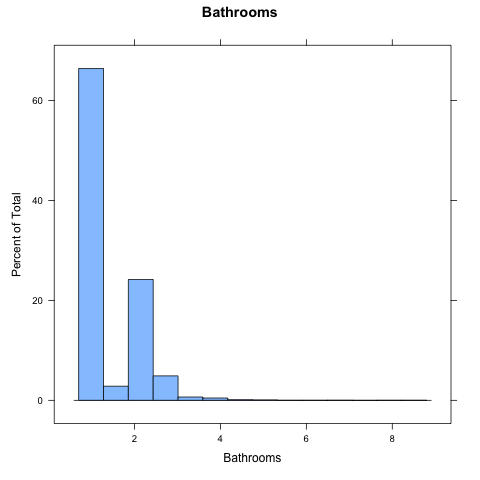

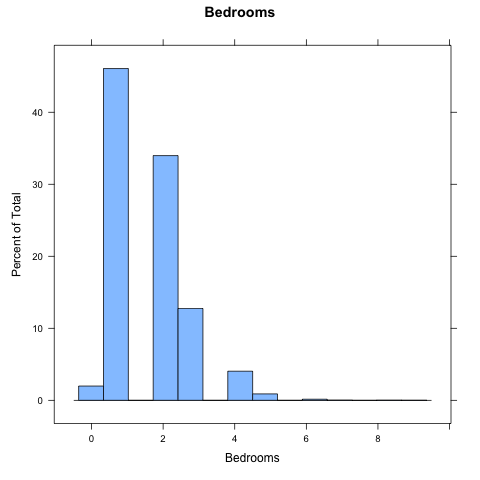

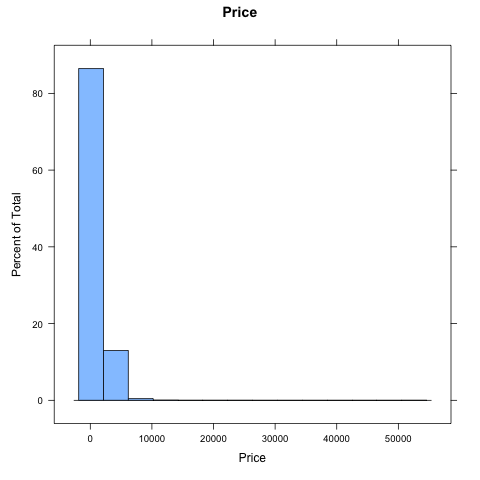

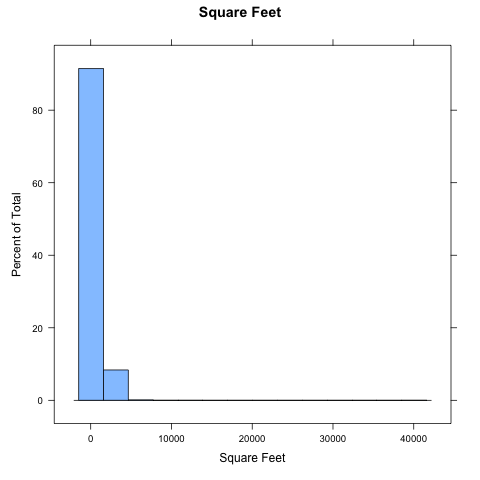

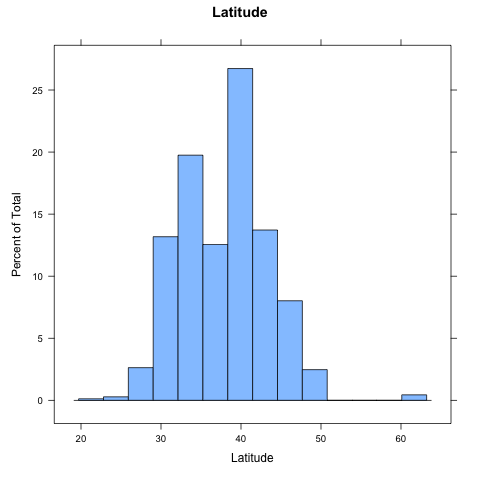

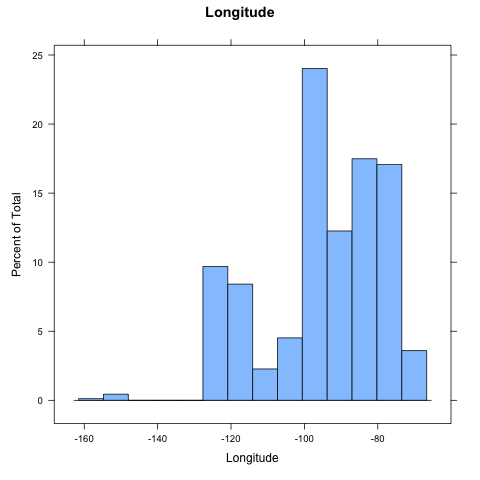

In [22]:
%%R

print(histogram(dfMedidas$bathrooms, main = "Bathrooms", xlab = "Bathrooms"))
print(histogram(dfMedidas$bedrooms, main = "Bedrooms", xlab = "Bedrooms"))
print(histogram(dfMedidas$price, main = "Price", xlab = "Price"))
print(histogram(dfMedidas$square_feet, main = "Square Feet", xlab = "Square Feet"))
print(histogram(dfMedidas$latitude, main = "Latitude", xlab = "Latitude"))
print(histogram(dfMedidas$longitude, main = "Longitude", xlab = "Longitude"))

Podemos ver que todas las variables siguen una distribución normal, y podemos destacar la siguiente información:

* Podemos ver que la mayoría de precios está por debajo de los 10000 y los metros cuadrados tambien.
* Podemos ver que los valores de Longitud se concentran entere 60 y 130 aproximadamente, lo que tiene sentido dado que los Estados Unidos de América están comprendidos entre esas longitudes.
* En cuanto al número de habitaciones y baños podemos ver que, en general, no son muchos.

Evaluamos también la presencia de outliers con los diagramas de caja

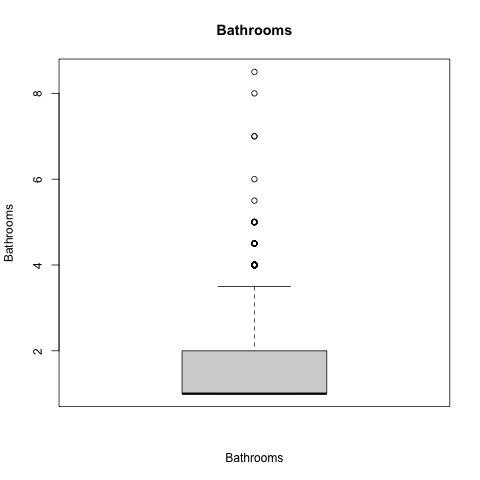

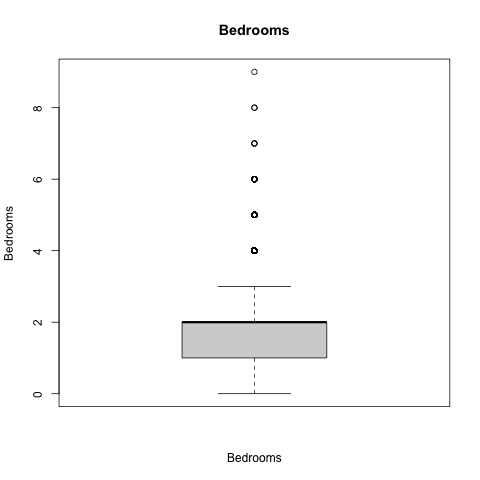

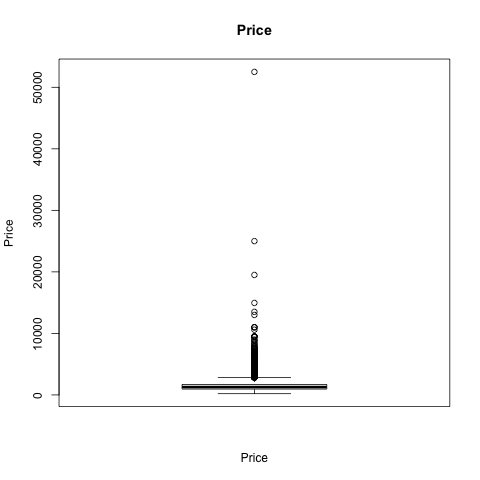

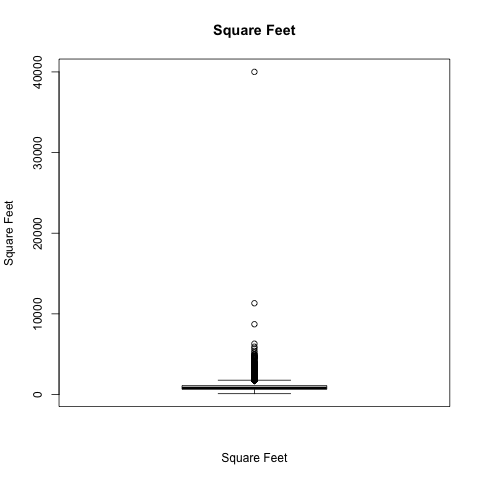

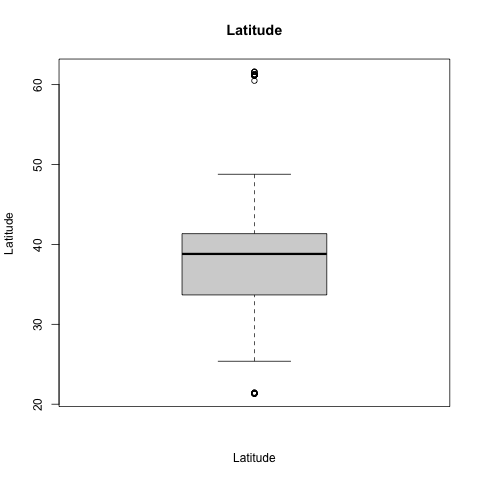

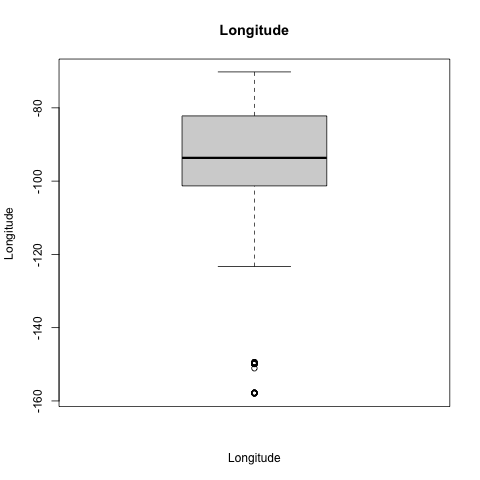

In [23]:
%%R
boxplot(dfMedidas$bathrooms, main = "Bathrooms", xlab = "Bathrooms", ylab = "Bathrooms")
boxplot(dfMedidas$bedrooms, main = "Bedrooms", xlab = "Bedrooms", ylab = "Bedrooms")
boxplot(dfMedidas$price, main = "Price", xlab = "Price", ylab = "Price")
boxplot(dfMedidas$square_feet, main = "Square Feet", xlab = "Square Feet", ylab = "Square Feet")
boxplot(dfMedidas$latitude, main = "Latitude", xlab = "Latitude", ylab = "Latitude")
boxplot(dfMedidas$longitude, main = "Longitude", xlab = "Longitude", ylab = "Longitude")

Podemos ver que todas las variables presentan Outliers, siendo el precio y los metros cuadrados aquellas variables con más, por ello, y para buscar alguna explicación, observamos el impacto de la localización geográfica en estas variables y la objetivo.

In addition: Warning messages:
1: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 
2: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 
3: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 


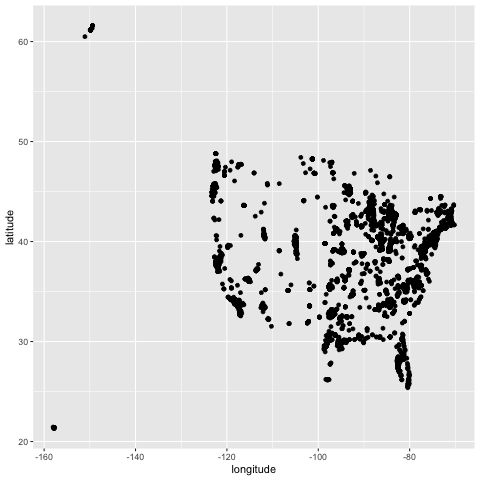

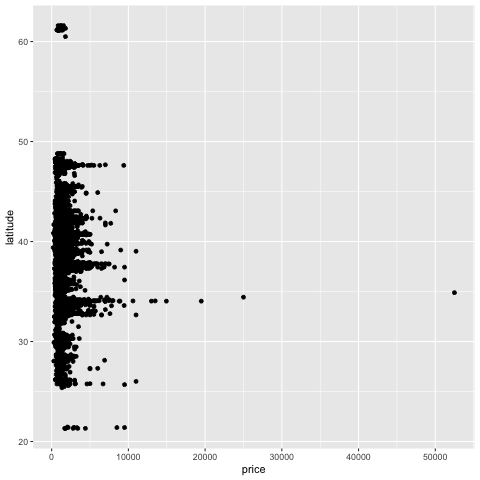

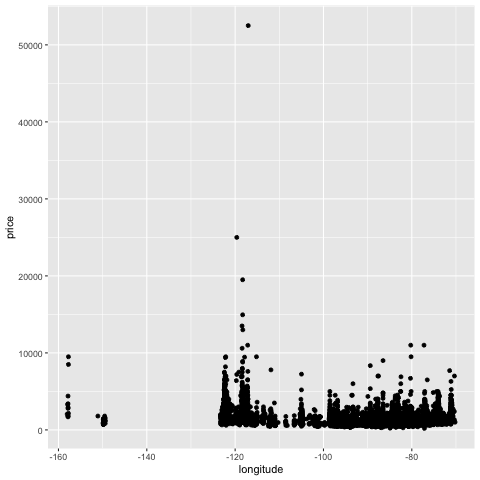

In [24]:
%%R
print(ggplot(dfMedidas, aes(x = longitude, y = latitude)) + geom_point())

print(ggplot(dfMedidas, aes(x = price, y = latitude)) + geom_point())
print(ggplot(dfMedidas, aes(x = longitude, y = price)) + geom_point())

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 
  


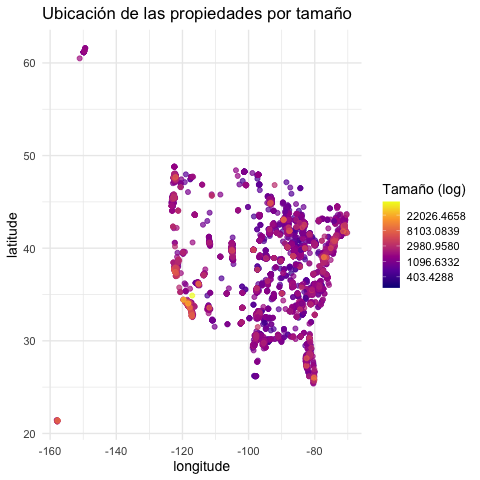

In [25]:
%%R

ggplot(dfMedidas, aes(x = longitude, y = latitude, color = price)) +
  geom_point(alpha = 0.7) +
  scale_color_viridis_c(option = "plasma", trans = "log") +
  labs(title = "Ubicación de las propiedades por tamaño",
       color = "Tamaño (log)") +
  theme_minimal(base_size = 14)

In addition: Warning messages:
1: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 
2: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 


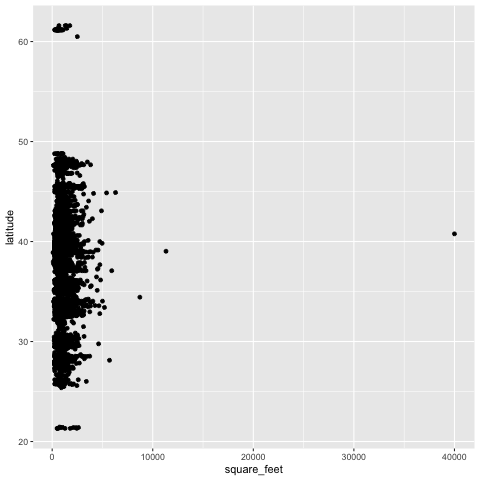

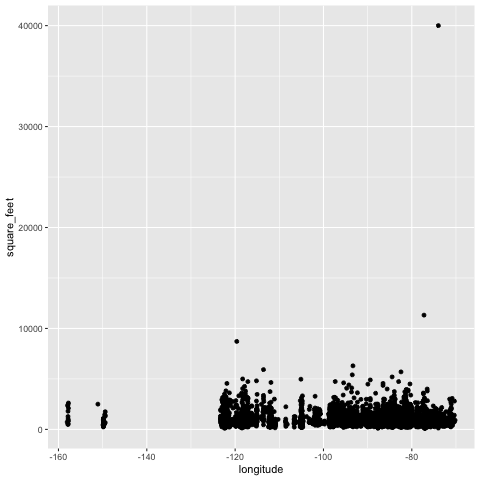

In [26]:
%%R
print(ggplot(dfMedidas, aes(x = square_feet, y = latitude)) + geom_point())
print(ggplot(dfMedidas, aes(x = longitude, y = square_feet)) + geom_point())

No hay una explicación geográfica del tamaño de las casas, por lo que se evalúa la relación con el tipo de casas (variable objetivo) 

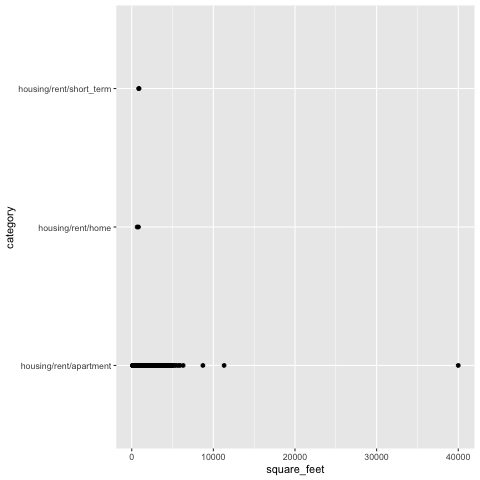

In [27]:
%%R
print(ggplot(dfMedidas, aes(x = square_feet, y = category)) + geom_point())

In [28]:
%%R
print(table(dfMedidas$category))
print(prop.table(table(dfMedidas$category))*100)


 housing/rent/apartment       housing/rent/home housing/rent/short_term 
                   9996                       2                       2 

 housing/rent/apartment       housing/rent/home housing/rent/short_term 
                  99.96                    0.02                    0.02 


De estas gráficas podemos sacar las siguientes conclusiones:

* En cuanto al precio de las viviendas, podemos observar que hay una zona geográfica que concentra los precios más altos (33/34º N, ~117º W).
* En cuanto al tamaño de las viviendas, podemos ver que las casas más grandes son de la categoria apartamento, siendo esta la categoria con más número de casas.

Por todo esto, se puede ver que los valores que en un principio pueden parecer atípicos, muestran información acerca de una concentración geográfica de casas de mayor precio, así como un mayor tamaño de una categoría concreta de casas.

## Análisis de Correlación:

### Correlación entre las variables numéricas:

In [29]:
%%R

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
corr_test <- corr.test(num_vars)

# Correlaciones
print(round(corr_test$r, 2))


            bathrooms bedrooms price square_feet latitude longitude  time
bathrooms        1.00     0.71  0.41        0.80    -0.05      0.00 -0.05
bedrooms         0.71     1.00  0.31        0.59     0.02      0.03  0.03
price            0.41     0.31  1.00        0.39     0.02     -0.18 -0.02
square_feet      0.80     0.59  0.39        1.00    -0.01      0.02  0.01
latitude        -0.05     0.02  0.02       -0.01     1.00     -0.11 -0.06
longitude        0.00     0.03 -0.18        0.02    -0.11      1.00 -0.19
time            -0.05     0.03 -0.02        0.01    -0.06     -0.19  1.00


Y de una forma más visual:

R callback write-console: In addition:   
R callback write-console: There were 40 warnings (use warnings() to see them)  
R callback write-console: 
  


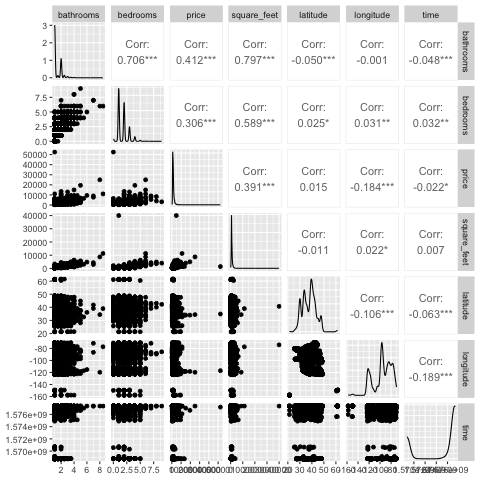

In [30]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
ggpairs(num_vars)

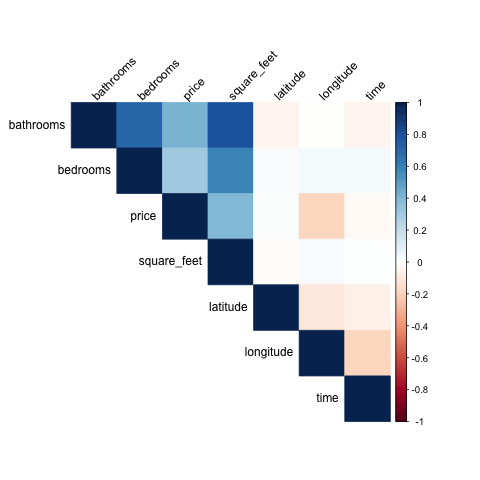

In [31]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
cor_matrix <- cor(num_vars, use = "complete.obs")

corrplot(corr_test$r,
        type = "upper", 
        method = "color", 
        tl.col = "black", 
        tl.srt = 45)

Podemos ver que las variables más relacionadas son el número de baños con los metros cuadrados (80%) y con el número de dormitorios (71%). 
Por otro lado, destaca la relación del número de dormitorios con el tamaño de la vivienda (60%)

Estas relaciones tienen sentido, ya que, el tamaño de una vivienda viene dado por la suma del tamaño de sus habitaciones (dormitorios y baños), y el número de baños está directamente relacionado con el de dormitorios, pues normalmente hay casi tantos de uno como de otro.

Estas relaciones significativas habrá que tenerlas en cuenta en el futuro, ya que, la informaciñon que aportan cada una de las variables de cada par puede llegar a ser redundante.


### Correlación con la variable objetivo:

Evaluamos la correlación de las variables numéricas con la variable objetivo

In [32]:
%%R
library(ggplot2)

target <- "category"
dfMedidas[[target]] <- as.numeric(as.factor(dfMedidas[[target]])) - 1

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
correlations <- cor(num_vars, use = "complete.obs", method = "pearson")[, target]

cor_df <- data.frame(
  Variable = names(correlations),
  Correlation = correlations
)
cor_df <- cor_df[cor_df$Variable != target, ]
cor_df <- cor_df[order(-abs(cor_df$Correlation)), ]

print(cor_df)

               Variable   Correlation
latitude       latitude -1.727350e-02
price             price -1.462970e-02
longitude     longitude  5.027233e-03
time               time  4.733065e-03
square_feet square_feet -3.740974e-03
bathrooms     bathrooms  3.178580e-03
bedrooms       bedrooms  4.282091e-05


Podemos ver que los valores no son lo suficientemente significativos como para tomar una decisión.

## Selección de Atributos:

Se descarta el uso de algoritmos de selección por filtrado debido a que es un problema de clasificación con la variable objetivo no numérica ordinal, por ello analizaremos la importancia de los atributos mediante ranking y embedido, para, de esta forma, poder evaluar la posibilidad de eliminar algún atributo más. 

### Selección por Ranking

Utilizamos Boruta como métrica de importancia de atributos

Boruta performed 99 iterations in 55.99382 secs.
 6 attributes confirmed important: bathrooms, latitude, longitude,
price, square_feet and 1 more;
 No attributes deemed unimportant.
 1 tentative attributes left: bedrooms;
             meanImp medianImp    minImp   maxImp  normHits  decision
bedrooms    1.365444  1.259645 -2.117438 7.927002 0.4444444 Tentative
bathrooms   4.291630  4.218142  2.151333 7.205519 0.9898990 Confirmed
square_feet 4.176461  4.345605  2.335721 6.055767 0.9898990 Confirmed
time        2.888841  2.634787  1.320500 5.500171 0.9090909 Confirmed
price       6.078947  6.067305  3.611757 8.849835 1.0000000 Confirmed
longitude   4.266121  4.208709  2.742395 5.981193 0.9898990 Confirmed
latitude    2.889322  2.755192  1.369280 4.556729 0.9292929 Confirmed


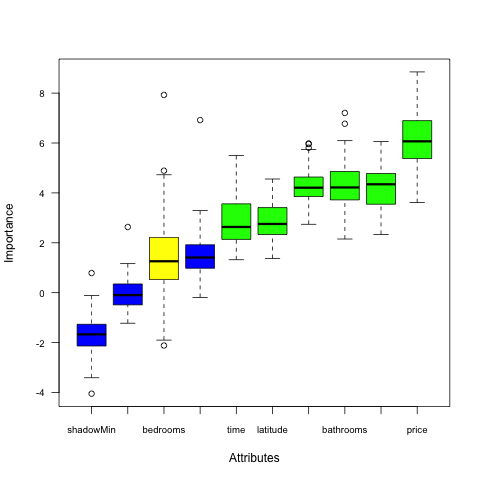

In [33]:
%%R
formula <- to_formula( c("latitude", "longitude", "price", "time", "square_feet",
                         "bathrooms", "bedrooms"), "category")


out.boruta <- Boruta(formula, data = dfMedidas)
plot(out.boruta, cex.axis = 0.8, las=1)
print(out.boruta)
attStats(out.boruta)

Podemos ver que los atributos más importante es el precio, seguido de longitude y square_feet. Destaca que un atributo, bedrooms, está catalogado como tentador mientras que el resto están marcados como útiles, sin embargo, el algoritmo no lo descarta como no importante.

### Selección por Embedido

Como criterio de embedido usaremos random forest, serán más importantes aquellos atributos usados en los árboles con menor error

In [34]:
%%R
modelo.rf <- randomForest(formula, data = dfMedidas, ntree=1000,
                          keep.forest=FALSE, importance=TRUE, na.action = na.roughfix)

rf_imp <- importance(modelo.rf, importance.type = 1)
print(rf_imp)

               %IncMSE IncNodePurity
latitude     5.2089976     1.7008387
longitude   10.7269662     1.7731280
price       11.4723532     1.6519636
time         4.0440994     1.9216907
square_feet  6.8960939     0.8257867
bathrooms    6.1822172     0.3857767
bedrooms     0.9945191     0.1253422


In addition: Warning message:
In randomForest.default(m, y, ...) :
  The response has five or fewer unique values.  Are you sure you want to do regression?


De nuevo podemos ver que las variables más importantes son longitude y price, con la variable bedrooms caracterizada por la poca importancia. Sin embargo, no podemos eliminar ninguna variable.

## Reducción de Dimensionalidad:

Aunque ya hemos realizado un estudio sobre la correlación de los atributos, ahora analizaremos más detalladamente si se puede o no considerar reducir la dimensionalidad del problema fusionando algunos.

In [35]:
%%R
atributos <- c("latitude", "longitude", "price", "time", "square_feet",
               "bathrooms", "bedrooms")

res.pca <- prcomp(na.roughfix(dfMedidas[,atributos]), scale = TRUE)
summary(res.pca)

Importance of components:
                          PC1    PC2    PC3    PC4     PC5     PC6     PC7
Standard deviation     1.5978 1.1092 1.0300 0.9270 0.78166 0.64306 0.52138
Proportion of Variance 0.3647 0.1758 0.1515 0.1228 0.08729 0.05908 0.03883
Cumulative Proportion  0.3647 0.5405 0.6920 0.8148 0.90209 0.96117 1.00000


Como podemos ver, a partir de 4 PCAs la varianza explicada es buena (>80%), sin embargo, se puede considerar que el mejor resultado es de 5 (~90%), ya que reduce la dimensionalidad sin perder apenas explicación.

In [36]:
%%R
pca_features <- as.data.frame(res.pca$x[, 1:5])
colnames(pca_features) <- paste0("PC", 1:5)
dfMedidas <- cbind(dfMedidas, pca_features)
dfMedidas <- dfMedidas[, !names(dfMedidas) %in% c("latitude", "longitude", "price", "time", "square_feet",
               "bathrooms", "bedrooms")]

In [37]:
%%R
head(dfMedidas)

  category has_photo price_type   cityname state    source       PC1
1        0 Thumbnail    Monthly Washington    DC RentLingo -2.266555
2        0 Thumbnail    Monthly Evansville    IN RentLingo -1.816844
3        0 Thumbnail    Monthly  Arlington    VA RentLingo -2.047535
4        0 Thumbnail    Monthly    Seattle    WA RentLingo -2.139540
5        0 Thumbnail    Monthly  Arlington    VA RentLingo -2.215125
6        0 Thumbnail    Monthly  Manhattan    NY  Listanza -1.649828
          PC2        PC3        PC4         PC5
1 -0.35841058  0.2688114  0.4922248 -1.00796573
2 -0.08638164  0.3660671  0.6108398 -0.07959856
3 -0.21931088  0.1968907  0.1995382 -1.38385800
4  2.12738085 -1.4285030  0.1941883  0.27103762
5 -0.33561828  0.2628639  0.4469570 -1.06013696
6 -0.05626600 -0.2012141 -0.0945132 -2.22742294


Ahora, hemos eliminado los atributos anteriores y los hemos sustituido por las PCAs seleccionadas previamente, reduciendo la dimensionalidad del problema.

Ahora, aplicaremos LDA para encontrar las combinaciones lineales de variables que separen los grupos.

In [38]:
%%R
set.seed(100495850)

entrena      <- createDataPartition(dfMedidas$category, p=0.6, list=FALSE)
setEntrena   <- dfMedidas[entrena,]
setValida    <- dfMedidas[-entrena,]

In [39]:
%%R
library(MASS)
par(mar=c(5,5,4,2))
options(repr.plot.width = 8, repr.plot.height = 5)

res.lda <- lda(category ~ PC1 + PC2 + PC3 + PC4 + PC5, data = setEntrena)
res.lda$scaling

            LD1        LD2
PC1 -0.06058822  0.2644273
PC2 -0.30217866  0.2031834
PC3  0.66420316 -0.3379879
PC4  0.26834028 -0.5523749
PC5  0.99187583  0.7892424


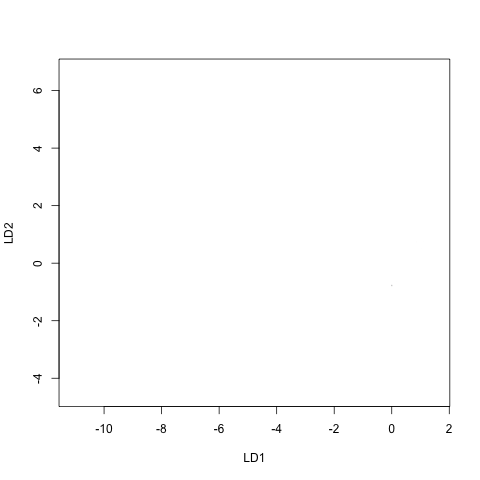

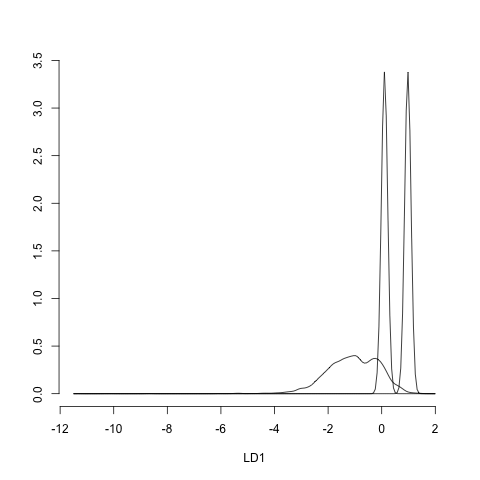

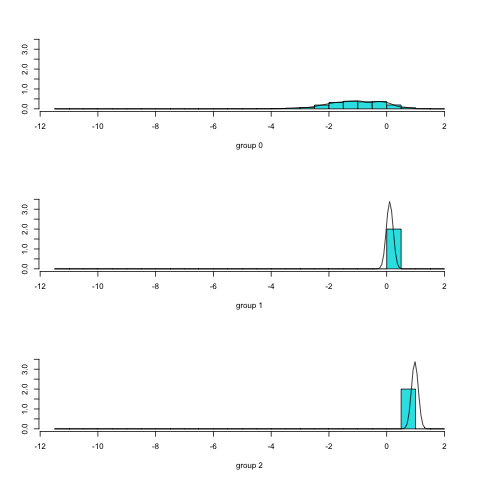

In [40]:
%%R
plot(res.lda,
     panel = function(x, y, ...) { points(x, y, cex = 2, ...) },
     col = as.integer(setEntrena$category), pch = 20)
plot(res.lda, dimen = 1, type ="density")
plot(res.lda, dimen = 1, type ="b")

Como podemos ver, LDA no es capaz de separar bien las clases, por lo que evaluamos si el dataset está desequilibrado

In [41]:
%%R
table(dfMedidas$category)
prop.table(table(dfMedidas$category)) * 100


    0     1     2 
99.96 

 0.02  0.02 


Como hemos visto en el dataset con más instancias, el problema persiste. Debido a esto, y para mantener un bajo coste computacional y energético, seguiremos con este dataset con menos instancias.

# Modelo

A la hora de elegir un modelo debemos tener en cuenta el alto desbalanceo de las clases, por lo que probaremos: SVM, Random Forest y XGBoost.

Antes de eso aplicamos un pipeline con un imputador para los valores faltantes, OneHot Encoding a las variables categóricas y SMOTE para el desequilibrio de clases:

## SVM

Agrupamos variables:

In [116]:
%%R
target <- "category"

num_vars <- c("PC1","PC2","PC3","PC4","PC5")
cat_vars <- c("has_photo","price_type","cityname","state","source")

vars <- c(target, num_vars, cat_vars)

Train Test Split:

Debido al bajo numero de instancias de las clases 1 y 2, se hace un split del 50%

In [117]:
%%R
set.seed(1)
sample <- createDataPartition(dfMedidas$category, p = 0.5, list = FALSE)

train <- dfMedidas[sample, vars]
test  <- dfMedidas[-sample, vars]

train$category <- as.factor(train$category)
test$category  <- as.factor(test$category)

In [118]:
%%R
print(table(dfMedidas$category))
print(table(train$category))
print(table(test$category))


   0    1    2 
9996    2    2 

   0    1    2 
4998    1    1 

   0    1    2 
4998    1    1 


Imputación: 
* Numéricas: Mediana
* Categóricas: Moda

In [119]:
%%R
# Numéricas
for (v in num_vars) {
  med <- median(train[[v]], na.rm = TRUE)
  train[[v]][is.na(train[[v]])] <- med
  test[[v]][is.na(test[[v]])] <- med
}

# Categóricas
Mode <- function(x) {
  ux <- na.omit(unique(x))
  ux[which.max(tabulate(match(x, ux)))]
}

for (v in cat_vars) {
  m <- Mode(train[[v]])
  train[[v]][is.na(train[[v]])] <- m
  test[[v]][is.na(test[[v]])] <- m
}

for (v in cat_vars) {
  train[[v]] <- factor(train[[v]])
  test[[v]]  <- factor(test[[v]], levels = levels(train[[v]]))
}

In [120]:
%%R
levels(train$category) <- make.names(levels(train$category))
levels(test$category)  <- levels(train$category)

Evitamos usar crossvalidation debido a la baja cantidad de instancias de las clases 1 y 2

In [122]:
%%R
print(length(pred))
print(length(test$category))

[1] 5000


Usamos pesos por calse en lugar de SMOTE debido a que este último necesita más de una instancia para poder generar artificialmente las instancias.

In [126]:
%%R
class_weights <- 1 / table(train$category)
class_weights <- class_weights / sum(class_weights)

model_svm <- svm(
  category ~ PC1 + PC2 + PC3 + PC4 + PC5 +
             has_photo + price_type + cityname + state + source,
  data = train,
  kernel = "linear",
  class.weights = class_weights
)

ok <- complete.cases(
  test[, c("PC1","PC2","PC3","PC4","PC5",
           "has_photo","price_type","cityname","state","source")]
)

pred <- predict(model_svm, test[ok, ])

confusionMatrix(pred, test$category[ok])

Confusion Matrix and Statistics

          Reference
Prediction   X0   X1   X2
        X0 4368    0    0
        X1   14    1    1
        X2   41    0    0

Overall Statistics
                                          
               Accuracy : 0.9873          
                 95% CI : (0.9836, 0.9904)
    No Information Rate : 0.9995          
    P-Value [Acc > NIR] : 1               
                                          
                  Kappa : 0.0502          
                                          
 Mcnemar's Test P-Value : 4.201e-12       

Statistics by Class:

                     Class: X0 Class: X1 Class: X2
Sensitivity            0.98757  1.000000  0.000000
Specificity            1.00000  0.996609  0.990732
Pos Pred Value         1.00000  0.062500  0.000000
Neg Pred Value         0.03509  1.000000  0.999772
Prevalence             0.99955  0.000226  0.000226
Detection Rate         0.98712  0.000226  0.000000
Detection Prevalence   0.98712  0.003616  0.009266
Balan

Podemos ver que el modelo detecta correctamente las instancias de la clase 0 (98.76%), la intancia de la clase 1, pero no la de la clase 2.

Por otro lado, podemos ver que, siempre que el modelo clasifica como clase 0 acierta, mientras que con las clases 1 y 2 falla un poco.

Por último, aunque el Balanced Accuracy sea > 90% para las clases 0 y 1 y del 50% pra la clase 2, estos valores están claramente influidos por las pocas instancias de las clases 1 y 2.

## Random Forest

Repetimos el mismo pipeline de antes:

In [132]:
%%R

# Variables
target <- "category"

num_vars <- c("PC1","PC2","PC3","PC4","PC5")
cat_vars <- c("has_photo","price_type","cityname","state","source")

vars <- c(target, num_vars, cat_vars)

# Train Test
set.seed(1)
sample <- createDataPartition(dfMedidas$category, p = 0.5, list = FALSE)

train <- dfMedidas[sample, vars]
test  <- dfMedidas[-sample, vars]

train$category <- as.factor(train$category)
test$category  <- as.factor(test$category)

# Imputacion
# Numéricas
for (v in num_vars) {
  med <- median(train[[v]], na.rm = TRUE)
  train[[v]][is.na(train[[v]])] <- med
  test[[v]][is.na(test[[v]])] <- med
}

# Categóricas
Mode <- function(x) {
  ux <- na.omit(unique(x))
  ux[which.max(tabulate(match(x, ux)))]
}

for (v in cat_vars) {
  m <- Mode(train[[v]])
  train[[v]][is.na(train[[v]])] <- m
  test[[v]][is.na(test[[v]])] <- m
}

for (v in cat_vars) {
  train[[v]] <- factor(train[[v]])
  test[[v]]  <- factor(test[[v]], levels = levels(train[[v]]))
}

levels(train$category) <- make.names(levels(train$category))
levels(test$category)  <- levels(train$category)


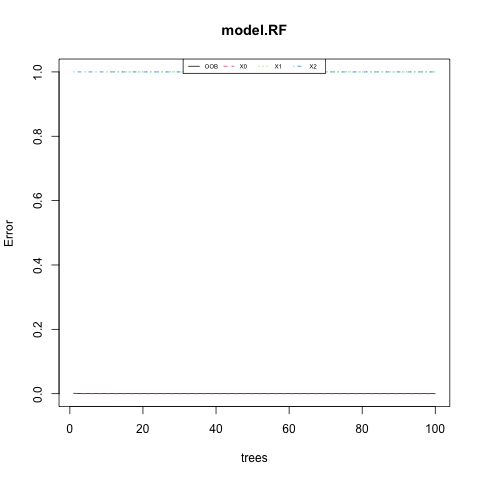

In [138]:
%%R
class_weights <- 1 / table(train$category)
class_weights <- class_weights / sum(class_weights)

set.seed(1)
model.RF <- randomForest(category ~ PC1 + PC2 + PC3 + PC4 + PC5 +
             has_photo + price_type + state + source,
                         data = train, ntree = 100, classwt = class_weights, importance = TRUE)
plot(model.RF)
model.RF.leyenda <- if (is.null(model.RF$test$err.rate)) {colnames(model.RF$err.rate)
                    } else {colnames(model.RF$test$err.rate)}
legend("top", cex =0.5, legend = model.RF.leyenda, lty=c(1,2,3,4), col=c(1,2,3,4), horiz = TRUE)

Como podemos ver, el modelo de Random Forest clasifica muy bien la clase mayoritaria, sin embargo, no es capaz de clasificar las clases 1 y 2.

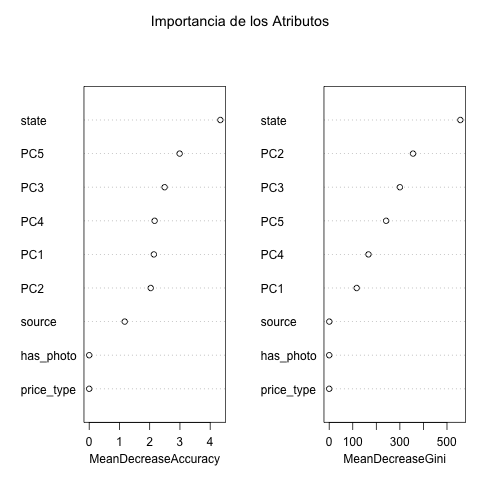

In [139]:
%%R
varImpPlot(model.RF, sort = TRUE, main = "Importancia de los Atributos")

Con estas gráficas podemos ver que las variables has_photo y price_type no aportan casi nada al modelo, mientras que state, PC5, PC3, PC4, son las más influyentes.

Por otro lado, podemos ver que las variables que más ayudan a dividir el árbol son PC3, PC2 y PC5.

## XGBoost

Aplicamos un pipeline

In [144]:
%%R
# Copias
train_xgb <- train
test_xgb  <- test

# Factores → numéricos
train_xgb[] <- lapply(train_xgb, function(x)
  if (is.factor(x)) as.numeric(x) else x)

test_xgb[] <- lapply(test_xgb, function(x)
  if (is.factor(x)) as.numeric(x) else x)

# Matrices X / y
X_train <- as.matrix(train_xgb[, setdiff(names(train_xgb), "category")])
y_train <- as.numeric(train$category) - 1

X_test  <- as.matrix(test_xgb[,  setdiff(names(test_xgb),  "category")])
y_test  <- as.numeric(test$category) - 1

# DMatrix
dtrain <- xgb.DMatrix(data = X_train, label = y_train)
dtest  <- xgb.DMatrix(data = X_test,  label = y_test)

# Pesos de clase (desequilibrio)
class_counts  <- table(y_train)
class_weights <- max(class_counts) / class_counts
weights_train <- as.numeric(class_weights[as.character(y_train)])

setinfo(dtrain, "weight", weights_train)

[1] TRUE


Parametros para XGBoost

In [145]:
%%R
params <- list(
  booster = "gbtree",
  objective = "multi:softprob",
  num_class = length(unique(y_train)),
  eval_metric = "mlogloss",

  eta = 0.05,
  max_depth = 6,
  min_child_weight = 5,
  subsample = 0.8,
  colsample_bytree = 0.8
)

Modelo:

In [146]:
%%R
set.seed(1)

model_xgb <- xgb.train(
  params = params,
  data = dtrain,
  nrounds = 500,
  watchlist = list(train = dtrain, test = dtest),
  early_stopping_rounds = 30,
  verbose = 1
)

Multiple eval metrics are present. Will use test_mlogloss for early stopping.
Will train until test_mlogloss hasn't improved in 30 rounds.

[1]	train-mlogloss:1.061886	test-mlogloss:1.025197 
[2]	train-mlogloss:0.991812	test-mlogloss:0.958769 
[3]	train-mlogloss:0.949213	test-mlogloss:0.897958 
[4]	train-mlogloss:0.921126	test-mlogloss:0.841731 
[5]	train-mlogloss:0.863054	test-mlogloss:0.790173 
[6]	train-mlogloss:0.866264	test-mlogloss:0.742280 
[7]	train-mlogloss:0.821335	test-mlogloss:0.698309 
[8]	train-mlogloss:0.800310	test-mlogloss:0.657275 
[9]	train-mlogloss:0.759409	test-mlogloss:0.619070 
[10]	train-mlogloss:0.713464	test-mlogloss:0.583526 
[11]	train-mlogloss:0.671065	test-mlogloss:0.550434 
[12]	train-mlogloss:0.631558	test-mlogloss:0.519438 
[13]	train-mlogloss:0.617268	test-mlogloss:0.490392 
[14]	train-mlogloss:0.596102	test-mlogloss:0.463303 
[15]	train-mlogloss:0.561763	test-mlogloss:0.437919 
[16]	train-mlogloss:0.529775	test-mlogloss:0.414075 
[17]	train-mlogloss:0

In addition: Warning message:
In throw_err_or_depr_msg("Parameter '", match_old, "' has been renamed to '",  :
  Parameter 'watchlist' has been renamed to 'evals'. This warning will become an error in a future version.


Evaluación:

In [147]:
%%R
pred_prob <- predict(model_xgb, dtest)
pred_matrix <- matrix(pred_prob, ncol = length(unique(y_train)), byrow = TRUE)

pred_class <- max.col(pred_matrix) - 1
pred_factor <- factor(pred_class, levels = 0:2)
true_factor <- factor(y_test, levels = 0:2)

confusionMatrix(pred_factor, true_factor)

Confusion Matrix and Statistics

          Reference
Prediction    0    1    2
         0 1692    1    0
         1 1660    0    1
         2 1646    0    0

Overall Statistics
                                          
               Accuracy : 0.3384          
                 95% CI : (0.3253, 0.3517)
    No Information Rate : 0.9996          
    P-Value [Acc > NIR] : 1               
                                          
                  Kappa : -3e-04          
                                          
 Mcnemar's Test P-Value : <2e-16          

Statistics by Class:

                      Class: 0 Class: 1 Class: 2
Sensitivity          0.3385354   0.0000   0.0000
Specificity          0.5000000   0.6677   0.6707
Pos Pred Value       0.9994093   0.0000   0.0000
Neg Pred Value       0.0003024   0.9997   0.9997
Prevalence           0.9996000   0.0002   0.0002
Detection Rate       0.3384000   0.0000   0.0000
Detection Prevalence 0.3386000   0.3322   0.3292
Balanced Accuracy    

Podemos ver que el modelo detecta algunas instancias de la clase 0 (33.9%) pero no la de las clases 1 y 2.

Por otro lado, podemos ver que, cuando el modelo clasifica como clase 0 acierta la mitad de las veces, mientras que con las clases 1 y 2 acierta cerca del 67% de las veces.

Por último, aunque el Balanced Accuracy sea ~ 40% para las clase 0 y > 33% pra las clases 1 y 2, estos valores están claramente influidos por las pocas instancias de las clases 1 y 2 además del intento por parte del modelo de distribuir equitativamente las instancias por cada clase.

# Conclusión

Debido al enorme desequilibrio de clases y las consecuentes pocas instancias de las clases 1 y 2, hasta los modelos que mejor funcionan para clases desequilibradas arrojan resultados alterados.

Tanto SVM como RF daban resultados excesivamente buenos, mientras que XGBoost ha dado un resultado excesivamente malo.

El problema venía desde el principio, con un dataset con 2 instancias tanto para la clase 1 como para la 2 estava abocado al fracaso.
El otro dataset disponible, aquel con 100K instancias, presentaba el mismo problema de desequilibrio, pero esta vez con 6 clases, intentar cualquier modelo de clasificación con este otro dataset habría dado un resultado similar a un coste computacional mucho mayor.